# Kinase Substrate-Set Tree vs Sequence Tree: Comparison Analysis

This notebook:
1. Builds two kinase trees — one from **substrate-set overlap** (screening data) and one from **kinase domain sequences**
2. **Aligns leaf order** between the two trees using a recursive child-swap heuristic (Optimal Leaf Ordering)
3. Computes four complementary **tree topology similarity metrics**:
   - Robinson-Foulds (RF) Distance
   - Matching Split Distance (MSD)
   - Matching Pair (MP) Metric
   - Mutual Clustering Information (MCI)
4. Produces a **discussion-ready report** on convergence and divergence between the two trees


## 1. Imports & Setup

In [182]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.cluster.hierarchy import linkage, dendrogram, to_tree, leaves_list, fcluster
from scipy.spatial.distance import squareform
from itertools import combinations
import warnings

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10


## 2. Tree-Building Functions (from `11_novel_ksi_analysis.py`)

### 2a. Substrate-set similarity tree

In [183]:
def _weighted_jaccard(u: np.ndarray, v: np.ndarray) -> float:
    num = np.minimum(u, v).sum()
    den = np.maximum(u, v).sum()
    return 0.0 if den == 0 else float(num / den)


def kinase_set_tree(
    kinase_to_subs,
    metric="jaccard",          # "jaccard" | "dice" | "overlap" | "weighted_jaccard"
    weights=None,
    linkage_method="average",
    figsize=(8, 4),
    title="Kinase substrate-set similarity (tree)"
):
    """Build a dendrogram from pairwise substrate-set similarity between kinases."""
    kinases = list(kinase_to_subs.keys())
    universe = sorted(set().union(*[set(kinase_to_subs[k]) for k in kinases]))

    if weights is None:
        X = np.zeros((len(kinases), len(universe)), dtype=np.uint8)
        col_index = {s: j for j, s in enumerate(universe)}
        for i, k in enumerate(kinases):
            for s in kinase_to_subs[k]:
                X[i, col_index[s]] = 1
        Xw = X.astype(float)
    else:
        Xw = np.zeros((len(kinases), len(universe)), dtype=float)
        col_index = {s: j for j, s in enumerate(universe)}
        for i, k in enumerate(kinases):
            wd = weights.get(k, {})
            for s, val in wd.items():
                if s in col_index:
                    Xw[i, col_index[s]] = float(val)

    n = len(kinases)
    D = np.zeros((n, n), dtype=float)

    for i in range(n):
        for j in range(i + 1, n):
            if metric == "jaccard":
                a, b = Xw[i] > 0, Xw[j] > 0
                inter = np.logical_and(a, b).sum()
                union = np.logical_or(a, b).sum()
                sim = 0.0 if union == 0 else inter / union
            elif metric == "dice":
                a, b = Xw[i] > 0, Xw[j] > 0
                inter = np.logical_and(a, b).sum()
                sim = 0.0 if (a.sum() + b.sum()) == 0 else (2 * inter) / (a.sum() + b.sum())
            elif metric == "overlap":
                a, b = Xw[i] > 0, Xw[j] > 0
                inter = np.logical_and(a, b).sum()
                sim = 0.0 if min(a.sum(), b.sum()) == 0 else inter / min(a.sum(), b.sum())
            elif metric == "weighted_jaccard":
                sim = _weighted_jaccard(Xw[i], Xw[j])
            else:
                raise ValueError(f"Unknown metric: {metric}")
            D[i, j] = D[j, i] = 1.0 - sim

    dist_df = pd.DataFrame(D, index=kinases, columns=kinases)
    condensed = D[np.triu_indices(n, k=1)]
    Z = linkage(condensed, method=linkage_method)

    plt.figure(figsize=figsize)
    dendrogram(Z, labels=kinases, orientation="right")
    plt.title(title + f"  (metric={metric}, linkage={linkage_method})")
    plt.tight_layout()
    plt.show()

    return dist_df, Z


### 2b. Newick export (substrate-set tree)

In [184]:
from scipy.cluster.hierarchy import to_tree as _to_tree

def _quote_newick_label(name):
    name = str(name)
    needs_quote = any(c in name for c in " ():,;[]\t\n\r'")
    if "'" in name:
        needs_quote = True
        name = name.replace("'", "''")
    return f"'{name}'" if needs_quote else name


def export_newick_exact(dist_df, Z, kinase_to_subs,
                        out_newick="screening_tree.newick", precision=10):
    """Export a Newick string matching the substrate-set linkage tree exactly."""
    labels = list(dist_df.index)
    if list(dist_df.columns) != labels:
        raise ValueError("dist_df columns must match dist_df.index order.")

    root, _ = _to_tree(Z, rd=True)

    def rec(node, parent_dist):
        node_dist = float(node.dist)
        bl = 0.0 if parent_dist is None else max(parent_dist - node_dist, 0.0)
        if node.is_leaf():
            nm = _quote_newick_label(labels[node.id])
            return nm if parent_dist is None else f"{nm}:{bl:.{precision}f}"
        left  = rec(node.left,  node_dist)
        right = rec(node.right, node_dist)
        subtree = f"({left},{right})"
        return subtree if parent_dist is None else f"{subtree}:{bl:.{precision}f}"

    newick = rec(root, None) + ";"
    with open(out_newick, "w") as f:
        f.write(newick + "\n")
    return out_newick, newick, root


### 2c. Sequence-based tree

In [185]:
import shutil, subprocess
from pathlib import Path

def export_sequence_tree_newick(
    kinase_to_seq, out_newick="kinase_seq_tree.newick",
    method="nj", mafft_path="mafft",
):
    """Build a sequence tree via MAFFT MSA → identity distance → NJ/UPGMA."""
    from Bio import AlignIO, Phylo
    from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor

    out_newick = Path(out_newick)

    def _sanitize(name):
        bad = " \t\n\r()[]{}:,;\"'"
        return "".join("_" if c in bad else c for c in str(name))

    records = [(_sanitize(k), str(seq).strip().upper())
               for k, seq in kinase_to_seq.items() if seq]
    if len(records) < 2:
        raise ValueError("Need at least 2 kinase sequences.")

    fasta_path = out_newick.with_suffix(".fasta")
    with open(fasta_path, "w") as f:
        for name, seq in records:
            f.write(f">{name}\n")
            for i in range(0, len(seq), 80):
                f.write(seq[i:i+80] + "\n")

    if shutil.which(mafft_path) is None:
        raise RuntimeError("MAFFT not found. Install via: conda install -c bioconda mafft")

    aln_path = out_newick.with_suffix(".aln.fasta")
    res = subprocess.run([mafft_path, "--auto", str(fasta_path)],
                         capture_output=True, text=True, check=True)
    aln_path.write_text(res.stdout)
    alignment = AlignIO.read(str(aln_path), "fasta")

    calculator = DistanceCalculator("identity")
    dm = calculator.get_distance(alignment)
    names = dm.names
    dist_df = pd.DataFrame(
        [[dm[i, j] for j in range(len(names))] for i in range(len(names))],
        index=names, columns=names
    )

    constructor = DistanceTreeConstructor()
    tree = constructor.nj(dm) if method == "nj" else constructor.upgma(dm)
    Phylo.write(tree, str(out_newick), "newick")
    return str(out_newick), out_newick.read_text().strip(), dist_df


def plot_sequence_dendrogram_from_dist(dist_df, linkage_method="average",
                                       orientation="right", figsize=(8, 5),
                                       title="Kinase sequence dendrogram"):
    labels = list(dist_df.index)
    D = dist_df.loc[labels, labels].values
    condensed = squareform(D, checks=False)
    Z = linkage(condensed, method=linkage_method)
    plt.figure(figsize=figsize)
    dendrogram(Z, labels=labels, orientation=orientation)
    plt.title(f"{title}  (linkage={linkage_method})")
    plt.tight_layout()
    plt.show()
    return Z


## 3. Load Data & Build Both Trees

> **Edit the paths below** to point to your data files.

In [186]:
# ── Load data ──────────────────────────────────────────────────────────────
blib_kinases_with_acc = pd.read_csv(
    '../screening_analysis/blib_kinases_with_acc.csv', header=None
)
blib_kinases_with_acc.columns = ['kinase_type', 'kinase', 'kinase_seq', 'kinase_acc']

blib_screen = pd.read_pickle('./251203_ksi_reduced_df_tp.pkl')

# Keep only kinases present in the screen
blib_kinases_with_acc = blib_kinases_with_acc.loc[
    blib_kinases_with_acc['kinase'].isin(blib_screen['kinase']), :
]
print(f"Kinases with sequences: {len(blib_kinases_with_acc)}")
print(f"Total screen rows:      {len(blib_screen)}")


Kinases with sequences: 23
Total screen rows:      34767


In [187]:
blib_screen_y.loc[blib_screen_y['fp_sub'],:]

,substrate,kinase,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,fp_sub,true_positive
1308,DGEDDGDYESPNEEE,FES_HUMAN,True,sh2,sh2,1,1,0.549975,0.549975,0.00000,0.00000,True,False
1309,DGEDDGDYESPNEEE,FRK_HUMAN,True,sh2,sh2,1,1,0.851395,0.851395,0.00000,0.00000,True,False
1310,DGEDDGDYESPNEEE,FYN_HUMAN,True,sh2,sh2,1,1,0.593198,0.593198,0.00000,0.00000,True,False
1311,DGEDDGDYESPNEEE,JAK2_HUMAN_1,True,sh2,sh2,1,1,0.638280,0.638280,0.00000,0.00000,True,False
1312,DGEDDGDYESPNEEE,KSYK_HUMAN,True,sh2,sh2,1,1,1.353164,1.353164,0.00000,0.00000,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11350,TEKEEDIYEVLPDDD,FYN_HUMAN,True,sh2,sh2,1,1,0.905368,0.905368,0.00000,0.00000,True,False
11351,TEKEEDIYEVLPDDD,JAK2_HUMAN_1,True,sh2,sh2,1,1,0.497909,0.497909,0.00000,0.00000,True,False
11352,TEKEEDIYEVLPDDD,KSYK_HUMAN,True,sh2,sh2,1,1,0.902111,0.902111,0.00000,0.00000,True,False
11353,TEKEEDIYEVLPDDD,TNK1_HUMAN,False,,sh2,1,0,0.135917,NaN,0.12300,NaN,True,False


In [188]:
# ── Filter true positives ──────────────────────────────────────────────────

# pY substrates (SH2-binding)
blib_screen_y = blib_screen.loc[blib_screen['paabd_all'] == 'sh2', :]
well_rep_y = (blib_screen_y.groupby('substrate')['kinase'].count()
                            .loc[lambda x: x > 3].index)
blib_screen_y = blib_screen_y.loc[
    blib_screen_y['substrate'].isin(well_rep_y) & blib_screen_y['lfsr_best_hit']<0.001, :
]

# pS/pT substrates
blib_screen_st = blib_screen.loc[blib_screen['paabd_all'] != 'sh2', :]
well_rep_st = (blib_screen_st.groupby('substrate')['kinase'].count()
                              .loc[lambda x: x > 6].index)
blib_screen_st = blib_screen_st.loc[
    blib_screen_st['substrate'].isin(well_rep_st) & (blib_screen_st['lfsr_best_hit']<0.001 ) & (blib_screen_st['fp_sub']==False), :
]

blib_screen_tp = pd.concat([blib_screen_st, blib_screen_y])
blib_screen_tp['kinase'] = blib_screen_tp['kinase'].str.replace('_HUMAN', '')
blib_kinases_with_acc['kinase'] = blib_kinases_with_acc['kinase'].str.replace('_HUMAN', '')

print(f"True positive rows: {len(blib_screen_tp)}")
print(f"Unique kinases:     {blib_screen_tp['kinase'].nunique()}")
print(f"Unique substrates:  {blib_screen_tp['substrate'].nunique()}")


True positive rows: 15068
Unique kinases:     23
Unique substrates:  3146


In [189]:
blib_screen_tp.loc[(blib_screen_tp['kinase']=='JAK2_1')&(blib_screen_tp['true_positive']),:]

,substrate,kinase,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,fp_sub,true_positive
564,AQVPVQKYNDIVHDL,JAK2_1,True,sh2,sh2,1,1,0.547273,0.547273,0.00000,0.00000,False,True
2029,EEDDEENYENVPRVL,JAK2_1,True,sh2,sh2,1,1,0.582713,0.582713,0.00000,0.00000,False,True
2312,EKEEEDIYEVLPDEE,JAK2_1,True,sh2,sh2,1,1,0.570739,0.570739,0.00000,0.00000,False,True
2662,ERPHSPHYYFNSAGV,JAK2_1,True,sh2,sh2,1,1,0.641256,0.641256,0.00000,0.00000,False,True
4588,IIDEEDTYTMPSTRD,JAK2_1,True,sh2,sh2,1,1,0.853046,0.853046,0.00000,0.00000,False,True
6070,LKKTDRIYAMKVVKK,JAK2_1,True,sh2,sh2,1,1,0.375253,0.375253,0.00000,0.00000,False,True
6253,LMPNNVIYRTPNSMV,JAK2_1,True,sh2,sh2,1,1,0.524194,0.524194,0.00000,0.00000,False,True
6359,LPQDKEYYKVKEPGE,JAK2_1,True,sh2,sh2,1,1,0.208462,0.208462,0.04775,0.04775,False,True
7512,NTTAMTIYENLAPVT,JAK2_1,True,sh2,sh2,1,1,0.681877,0.681877,0.00000,0.00000,False,True
7657,PDEPIAFYAMGRGSP,JAK2_1,True,sh2,sh2,1,1,0.959727,0.959727,0.00000,0.00000,False,True


In [190]:
blib_screen_tp.loc[(blib_screen_tp['kinase']=='TNK1')&(blib_screen_tp['true_positive']),:]

,substrate,kinase,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,fp_sub,true_positive
305,AISEYGMYAKRHVPQ,TNK1,True,sh2,sh2,1,1,0.516887,0.516887,0.000,0.000,False,True
1471,DLAMYKTYKEKSVMM,TNK1,True,sh2,sh2,1,1,0.525921,0.525921,0.000,0.000,False,True
2229,EHAPAEMYDIMKTCW,TNK1,True,sh2,sh2,1,1,0.593639,0.593639,0.000,0.000,False,True
2829,FAGKEQTYYQGRHLG,TNK1,True,sh2,sh2,1,1,1.154422,1.154422,0.000,0.000,False,True
3314,GDTLYAPYSTHFQLQ,TNK1,True,sh2,sh2,1,1,0.359031,0.359031,0.001,0.001,False,True
4396,IAADKGHYKFCELLI,TNK1,True,sh2,sh2,1,1,0.434451,0.434451,0.000,0.000,False,True
4419,ICAGTDRYCMYKTGP,TNK1,True,sh2,sh2,1,1,0.560988,0.560988,0.000,0.000,False,True
4501,IEQIGLLYQEYRDKS,TNK1,True,sh2,sh2,1,1,0.571367,0.571367,0.000,0.000,False,True
10491,SHSFRGAYGLAMKVA,TNK1,True,sh2,sh2,1,1,0.435917,0.435917,0.000,0.000,False,True
12596,VYGVSPNYDKWEMER,TNK1,True,sh2,sh2,1,1,0.545717,0.545717,0.000,0.000,False,True


In [191]:
blib_screen_tp.groupby(['kinase','true_positive']).count()

substrate  positive  paabd_hit  paabd_all  \
kinase       true_positive                                              
ABL2         False                919       919        919        919   
             True                  78        78         78         78   
ADCK1        True                  32        32         32         32   
FES          False               1197      1197       1197       1197   
             True                 159       159        159        159   
FRK          False               1676      1676       1676       1676   
             True                  49        49         49         49   
FYN          False               1425      1425       1425       1425   
             True                 187       187        187        187   
IKKB         True                  80        80         80         80   
JAK2_1       False               1801      1801       1801       1801   
             True                  13        13         13         13   
KGP1         True                 221       221        221        221   
KKCC1        True                 470       470        470        470   
KS6B1_active True                 488       488        488        488   
KS6B1_wt     True                 475       475        475        475   
KSYK         False               1381      1381       1381       1381   
             True                 152       152        152        152   
M3K7         True                 121       121        121        121   
MAST1        True                  46        46         46         46   
PDPK1        True                 171       171        171        171   
PHKG1        True                 259       259        259        259   
PIM1         True                  27        27         27         27   
PLK1         True                 331       331        331        331   
PLK1_active  True                 358       358        358        358   
STYK1        False                735       735        735        735   
             True                  79        79         79         79   
TBK1         True                 323       323        323        323   
TITIN        True                   9         9          9          9   
TNK1         False               1796      1796       1796       1796   
             True                  10        10         10         10   

                            n_paabd  hit_count  binding_max  binding_best_hit  \
kinase       true_positive                                                      
ABL2         False              919        919          919                14   
             True                78         78           78                78   
ADCK1        True                32         32           32                32   
FES          False             1197       1197         1197                16   
             True               159        159          159               159   
FRK          False             1676       1676         1676                20   
             True                49         49           49                49   
FYN          False             1425       1425         1425                19   
             True               187        187          187               187   
IKKB         True                80         80           80                80   
JAK2_1       False             1801       1801         1801                10   
             True                13         13           13                13   
KGP1         True               221        221          221               221   
KKCC1        True               470        470          470               470   
KS6B1_active True               488        488          488               488   
KS6B1_wt     True               475        475          475               475   
KSYK         False             1381       1381         1381                19   
             True               152        152          152               152  

In [192]:
# ── Build substrate-set dictionary ────────────────────────────────────────
kinase_to_subs = (
    blib_screen_tp.loc[:, ['kinase', 'substrate']]
    .groupby('kinase')['substrate']
    .apply(lambda s: set(s.dropna().astype(str)))
    .to_dict()
)
print(f"Kinases in substrate-set dict: {len(kinase_to_subs)}")


Kinases in substrate-set dict: 23


Building substrate-set similarity tree (Jaccard, UPGMA) …


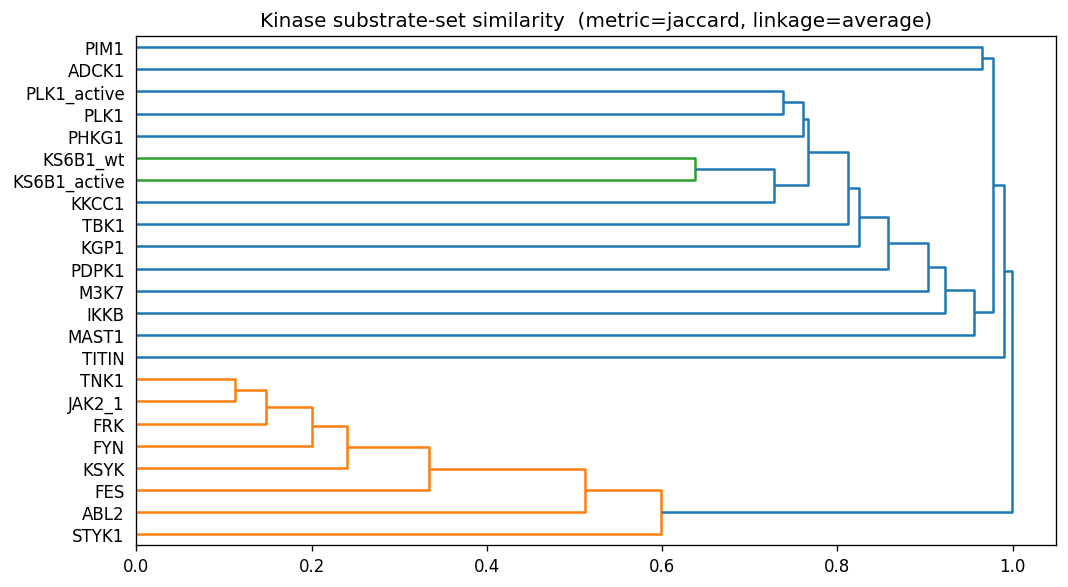

  Screening tree: 23 kinases


In [193]:
# ── Build screening (substrate-set) tree ──────────────────────────────────
print("Building substrate-set similarity tree (Jaccard, UPGMA) …")
dist_df_screen, Z_screen = kinase_set_tree(
    kinase_to_subs,
    metric="jaccard",
    linkage_method="average",
    figsize=(9, 5),
    title="Kinase substrate-set similarity"
)
labels_screen = list(dist_df_screen.index)
print(f"  Screening tree: {len(labels_screen)} kinases")


In [194]:
# ── Export Newick for screening tree ─────────────────────────────────────
path, newick_screen, root = export_newick_exact(
    dist_df_screen, Z_screen, kinase_to_subs, "screening_tree.newick"
)
print("Screening tree Newick saved →", path)


Screening tree Newick saved → screening_tree.newick


Building sequence-based tree (MAFFT → NJ) …
  Sequence tree: 23 kinases

Sequence dendrogram:


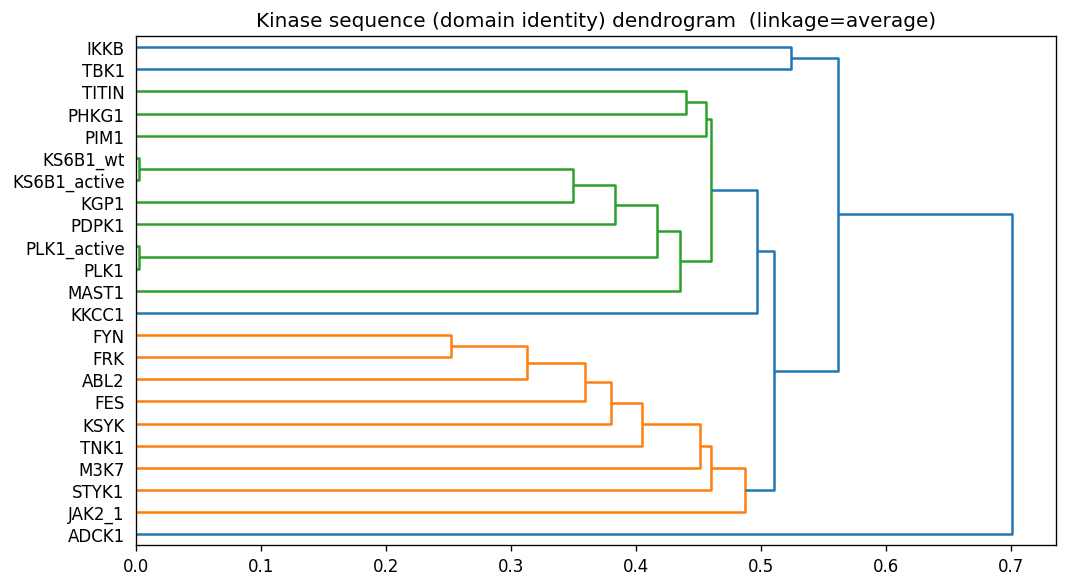

In [195]:
# ── Build sequence tree ───────────────────────────────────────────────────
kinase_to_seq = (
    blib_kinases_with_acc.loc[:, ['kinase', 'kinase_seq']]
    .set_index('kinase')['kinase_seq']
    .to_dict()
)

print("Building sequence-based tree (MAFFT → NJ) …")
newick_path, newick_str, dist_df_seq = export_sequence_tree_newick(
    kinase_to_seq, method="nj"
)

Z_seq, labels_seq = (lambda df: (
    linkage(squareform(df.values, checks=False), method="average"),
    list(df.index)
))(dist_df_seq)

print(f"  Sequence tree: {len(labels_seq)} kinases")

print("\nSequence dendrogram:")
Z_seq = plot_sequence_dendrogram_from_dist(
    dist_df_seq, linkage_method="average", figsize=(9, 5),
    title="Kinase sequence (domain identity) dendrogram"
)


## 4. Optimal Leaf Ordering — Align Screening Tree to Sequence Tree

We use a **recursive child-swap heuristic**: for every internal node in the screening tree, 
we optionally swap its two subtrees so that the median leaf-position of the left child 
is always ≤ that of the right child, relative to the reference (sequence) leaf order.

This maximises visual similarity between the two dendrograms without altering any branch 
lengths or topology — only the left/right drawing order of each fork is changed.


In [196]:
# ── Helper functions for OLO ──────────────────────────────────────────────

def _node_leaf_indices(node):
    """Return leaf indices below this ClusterNode (pre-order)."""
    if node.is_leaf():
        return [node.id]
    return _node_leaf_indices(node.left) + _node_leaf_indices(node.right)


def _median_position(node, order_map):
    leaves = _node_leaf_indices(node)
    return np.median([order_map.get(l, 0) for l in leaves])


def _swap_to_match(node, order_map):
    """Recursively swap children so left subtree median ≤ right subtree median."""
    if node.is_leaf():
        return
    _swap_to_match(node.left, order_map)
    _swap_to_match(node.right, order_map)
    if _median_position(node.left, order_map) > _median_position(node.right, order_map):
        node.left, node.right = node.right, node.left


def _tree_to_linkage(root, n_leaves):
    """Reconstruct linkage matrix from a (possibly reordered) ClusterNode tree."""
    rows = []
    next_id = [n_leaves]

    def _rec(node):
        if node.is_leaf():
            return node.id
        left_id  = _rec(node.left)
        right_id = _rec(node.right)
        new_id = next_id[0]
        next_id[0] += 1
        n = node.count if hasattr(node, "count") else len(_node_leaf_indices(node))
        rows.append([float(left_id), float(right_id), float(node.dist), float(n)])
        return new_id

    _rec(root)
    return np.array(rows)


def reorder_linkage_to_match(Z_target, Z_reference, labels_target, labels_reference,
                              figsize=(16, 6),
                              title_target="Screening tree (leaf-order aligned)",
                              title_reference="Sequence tree",
                              plot=True):
    """
    Swap child-node pairs in Z_target so its leaf traversal order 
    best matches Z_reference.  Topology and branch lengths are unchanged.
    
    Returns
    -------
    Z_reordered : np.ndarray  — new linkage matrix
    reordered_labels : list   — leaf labels in new traversal order
    """
    if set(labels_target) != set(labels_reference):
        common = sorted(set(labels_target) & set(labels_reference))
        warnings.warn(
            f"Label mismatch: using {len(common)} common kinases "
            f"({len(labels_target)} in screening, {len(labels_reference)} in sequence)."
        )
        labels_target    = [l for l in labels_target    if l in common]
        labels_reference = [l for l in labels_reference if l in common]

    ref_order = [labels_reference[i] for i in leaves_list(Z_reference)]
    ref_pos   = {label: pos for pos, label in enumerate(ref_order)}
    order_map = {i: ref_pos.get(labels_target[i], i) for i in range(len(labels_target))}

    root, _ = to_tree(Z_target, rd=True)
    _swap_to_match(root, order_map)
    Z_reordered      = _tree_to_linkage(root, n_leaves=len(labels_target))
    reordered_labels = [labels_target[i] for i in leaves_list(Z_reordered)]

    if plot:
        fig, axes = plt.subplots(1, 2, figsize=figsize)
        dendrogram(Z_reordered, labels=labels_target,    orientation="right", ax=axes[0])
        axes[0].set_title(title_target, fontsize=11)
        dendrogram(Z_reference, labels=labels_reference, orientation="right", ax=axes[1])
        axes[1].set_title(title_reference, fontsize=11)
        plt.suptitle("Leaf-order-aligned dendrograms", fontsize=13, y=1.01)
        plt.tight_layout()
        plt.savefig("kinase_aligned_dendrograms.png", dpi=150, bbox_inches="tight")
        plt.show()
        print("Figure saved → kinase_aligned_dendrograms.png")

    return Z_reordered, reordered_labels


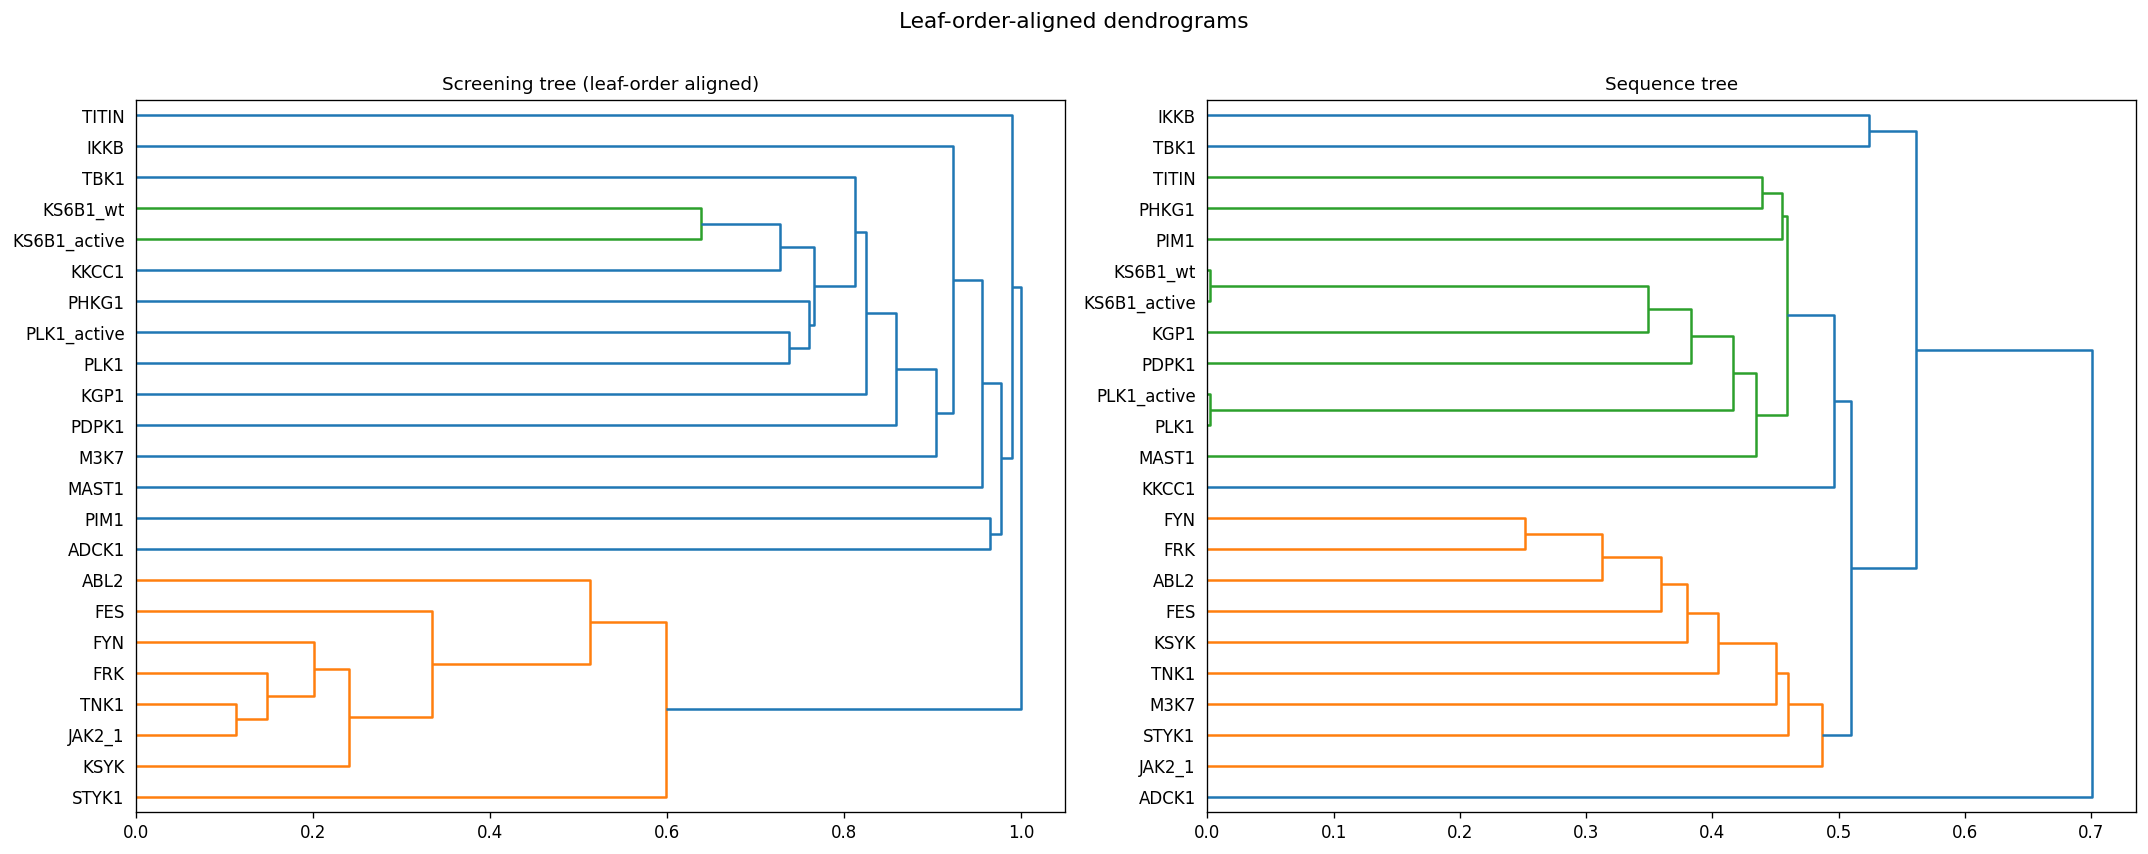

Figure saved → kinase_aligned_dendrograms.png

Leaf order after alignment (23 kinases):
    1.  STYK1
    2.  KSYK
    3.  JAK2_1
    4.  TNK1
    5.  FRK
    6.  FYN
    7.  FES
    8.  ABL2
    9.  ADCK1
   10.  PIM1
   11.  MAST1
   12.  M3K7
   13.  PDPK1
   14.  KGP1
   15.  PLK1
   16.  PLK1_active
   17.  PHKG1
   18.  KKCC1
   19.  KS6B1_active
   20.  KS6B1_wt
   21.  TBK1
   22.  IKKB
   23.  TITIN


In [197]:
# ── Run OLO alignment ─────────────────────────────────────────────────────
Z_screen_aligned, labels_aligned = reorder_linkage_to_match(
    Z_screen, Z_seq,
    labels_screen, labels_seq,
    figsize=(18, 7),
)

print(f"\nLeaf order after alignment ({len(labels_aligned)} kinases):")
for i, k in enumerate(labels_aligned):
    print(f"  {i+1:3d}.  {k}")


In [198]:
pd.read_pickle('../kinase_ml/data/human_kinome_seq_230301.pkl')

,kinase_gene,kinase_name,pk_group,pk_family,pk_subfamily,kinase,kinase_seq,kinseq_len,kinase_coord
0,AAK1,AP2-associated protein kinase 1,Other,NAK,NaN,Q2M2I8,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,961,"[[46, 315]]"
1,ABL1,Tyrosine-protein kinase ABL1,TK,Abl,NaN,P00519,MLEICLKLVGCKSKKGLSSSSSCYLEEALQRPVASDFEPQGLSEAA...,1130,"[[242, 493]]"
2,ABL2,Abelson tyrosine-protein kinase 2,TK,Abl,NaN,P42684,MGQQVGRVGEAPGLQQPQPRGIRGSSAARPSGRRRDPAGRTTETGF...,1182,"[[288, 539]]"
3,ACK,Activated CDC42 kinase 1,TK,Ack,NaN,Q07912,MQPEEGTGWLLELLSEVQLQQYFLRLRDDLNVTRLSHFEYVKNEDL...,1038,"[[126, 385]]"
4,ACTR2,Activin receptor type-2A,TKL,STKR,STKR2,P27037,MGAAAKLAFAVFLISCSSGAILGRSETQECLFFNANWEKDRTNQTG...,513,"[[192, 485]]"
...,...,...,...,...,...,...,...,...,...
294,GCN2,Eukaryotic translation initiation factor 2-alp...,Other,PEK,GCN2,Q9P2K8,MAGGRGAPGRGRDEPPESYPQRQDHELQALEAIYGADFQDLRPDAC...,1649,"[[590, 1001]]"
421,JAK1,Tyrosine-protein kinase JAK1,TK,Jak,NaN,P23458,MQYLNIKEDCNAMAFCAKMRSSKKTEVNLEAPEPGVEVIFYLSDRE...,1155,"[[875, 1152]]"
422,JAK2,Tyrosine-protein kinase JAK2,TK,Jak,NaN,O60674,MGMACLTMTEMEGTSTSSIYQNGDISGNANSMKQIDPVLQVYLYHS...,1132,"[[849, 1126]]"
423,JAK3,Tyrosine-protein kinase JAK3,TK,Jak,NaN,P52333,MAPPSEETPLIPQRSCSLLSTEAGALHVLLPARGPGPPQRLSFSFG...,1124,"[[822, 1122]]"


1. Clear separation of ST kinases and Y kinases, Clear separation of disctinct sub-clusters, with JAK2_1, TNK1,ADCK1, TITIN, PIM1, and interestingly MAST1 having individual orphan nodes showcasing their unique specificity from other families. These kinases' kinase domain sequences are also clustered phylogenetically as individual spanning nodes.
2. Evolutionary divergence-wise MAST1 is closer to PDK1,KPG1 and KS6B than PHKG and KKCC1, but in screening its selectivity is further away from these group of kinases
3. M3K7 kinase domain similarity matched closer to tyrosine kinases, and its selectivity against the S/T substrate library is indeed further away compared to other S/T kinases
4. TBK1 and IKKb are closely related kinase domain wise but differs in the substrate hits
5. Evolutionary trend of ABL2->FRK->FYN, preserved. But what is interesting and not fully aligned with the evolution is that FYN being the most generous on selectivity among the three and grouped closer to other promiscuous kinases such as FES 
6. Point phosphomimetic mutations for constitutively active kinase still group closest to the WT version, partially suggesting the mutation does not do much when screening only kinase domain region
ST kinases display less nested tree structures suggesting higher kinase-domain determining specificity
7. we mutated Ser 177 and 181 for IKKβ to E for encouraging the literature-reported activated form, but it may potentially pushes the substrate selectivity away from WT activation, making it grouped further away from S/T kinases


## 5. Tree Similarity Metric Functions

Four metrics are implemented, each capturing a different aspect of tree similarity.


### 5a. Robinson-Foulds (RF) Distance

In [199]:
def _get_bipartitions(Z, labels):
    """Return all bipartitions (splits) of the tree as frozensets-of-frozensets."""
    n = len(labels)
    root, nodelist = to_tree(Z, rd=True)

    def leaves_below(node):
        if node.is_leaf():
            return frozenset([labels[node.id]])
        return leaves_below(node.left) | leaves_below(node.right)

    all_leaves = frozenset(labels)
    splits = set()
    for node in nodelist[n:]:
        side_a = leaves_below(node)
        side_b = all_leaves - side_a
        if side_a and side_b:
            splits.add(frozenset([side_a, side_b]))
    return splits


def robinson_foulds(Z1, labels1, Z2, labels2):
    """
    Robinson-Foulds distance: counts bipartitions unique to each tree.
    
    rf_normalized = 0 → identical topology
    rf_normalized = 1 → maximally discordant
    """
    splits1 = _get_bipartitions(Z1, labels1)
    splits2 = _get_bipartitions(Z2, labels2)
    only1   = splits1 - splits2
    only2   = splits2 - splits1
    rf      = len(only1) + len(only2)
    rf_max  = 2 * (len(set(labels1) & set(labels2)) - 2)

    return {
        "rf_distance"      : rf,
        "rf_max"           : rf_max,
        "rf_normalized"    : rf / rf_max if rf_max > 0 else 0.0,
        "splits_only_in_T1": only1,
        "splits_only_in_T2": only2,
    }


### 5b. Matching Split Distance (MSD)

In [200]:
def matching_split_distance(Z1, labels1, Z2, labels2):
    """
    For each split in T1, find the best-matching split in T2 (min symmetric
    difference on smaller partition side); sum and average bidirectionally.
    More robust than RF to single-leaf perturbations.
    """
    universe = frozenset(set(labels1) & set(labels2))

    def _restrict(splits):
        out = []
        for sp in splits:
            sides = list(sp)
            s0, s1 = sides[0] & universe, sides[1] & universe
            if s0 and s1:
                out.append(frozenset([frozenset(s0), frozenset(s1)]))
        return out

    def _sym_diff(sp_a, sp_b):
        a = sorted(list(sp_a), key=len)
        b = sorted(list(sp_b), key=len)
        return min(len(a[0].symmetric_difference(b[0])),
                   len(a[0].symmetric_difference(b[1])))

    def _directed(source, target):
        return sum(
            min((_sym_diff(s, t) for t in target), default=len(universe))
            for s in source
        )

    sp1 = _restrict(_get_bipartitions(Z1, labels1))
    sp2 = _restrict(_get_bipartitions(Z2, labels2))
    d12, d21 = _directed(sp1, sp2), _directed(sp2, sp1)
    msd = (d12 + d21) / 2

    return {
        "msd"            : msd,
        "msd_normalized" : msd / len(universe) if universe else 0,
        "directed_T1→T2" : d12,
        "directed_T2→T1" : d21,
    }


### 5c. Matching Pair (MP) Metric

In [201]:
def _pair_merge_heights(Z, labels):
    """Map every leaf pair (a,b) -> height at which they first merge."""
    root, _ = to_tree(Z, rd=True)
    pair_height = {}

    def _rec(node):
        if node.is_leaf():
            return {labels[node.id]}
        left_set  = _rec(node.left)
        right_set = _rec(node.right)
        for a in left_set:
            for b in right_set:
                pair_height[tuple(sorted([a, b]))] = node.dist
        return left_set | right_set

    _rec(root)
    return pair_height


def matching_pair_metric(Z1, labels1, Z2, labels2):
    """
    Compares the rank-order of all pairwise merge heights between the two trees.
    - Spearman ρ = 1 → identical pair-ordering
    - Spearman ρ ≈ 0 → no correspondence
    """
    common = sorted(set(labels1) & set(labels2))
    ph1 = _pair_merge_heights(Z1, labels1)
    ph2 = _pair_merge_heights(Z2, labels2)

    keys  = [tuple(sorted(p)) for p in combinations(common, 2)]
    h1    = pd.Series({k: ph1.get(k, np.inf) for k in keys})
    h2    = pd.Series({k: ph2.get(k, np.inf) for k in keys})
    r1, r2 = h1.rank(), h2.rank()

    spearman = r1.corr(r2, method="spearman")
    kendall  = r1.corr(r2, method="kendall")
    mp_frac  = ((r1 - r2).abs() > 0).mean()

    return {
        "mp_fraction_discordant_pairs": float(mp_frac),
        "spearman_rank_correlation"   : float(spearman),
        "kendall_rank_correlation"    : float(kendall),
        "n_pairs"                     : len(keys),
    }


### 5d. Mutual Clustering Information (MCI)

In [202]:
def mutual_clustering_information(Z1, labels1, Z2, labels2, n_cuts=20):
    """
    Cut both trees at n_cuts evenly-spaced heights and compute AMI/NMI
    between the resulting flat clusterings at each level.
    
    mean_AMI = 0 → no shared clustering structure
    mean_AMI = 1 → identical clustering at all resolutions
    """
    from sklearn.metrics import adjusted_mutual_info_score, normalized_mutual_info_score

    common = sorted(set(labels1) & set(labels2))
    idx1 = [labels1.index(c) for c in common]
    idx2 = [labels2.index(c) for c in common]

    h_max   = max(Z1[:, 2].max(), Z2[:, 2].max())
    heights = np.linspace(1e-6, h_max, n_cuts)

    ami_scores, nmi_scores, valid_heights = [], [], []
    for h in heights:
        cl1 = fcluster(Z1, t=h, criterion="distance")[idx1]
        cl2 = fcluster(Z2, t=h, criterion="distance")[idx2]
        if len(np.unique(cl1)) < 2 or len(np.unique(cl2)) < 2:
            continue
        ami_scores.append(adjusted_mutual_info_score(cl1, cl2))
        nmi_scores.append(normalized_mutual_info_score(cl1, cl2))
        valid_heights.append(h)

    return {
        "mean_AMI"               : float(np.mean(ami_scores)) if ami_scores else np.nan,
        "mean_NMI"               : float(np.mean(nmi_scores)) if nmi_scores else np.nan,
        "std_AMI"                : float(np.std(ami_scores))  if ami_scores else np.nan,
        "n_height_cuts_evaluated": len(ami_scores),
        "ami_by_height"          : ami_scores,
        "nmi_by_height"          : nmi_scores,
        "heights_evaluated"      : valid_heights,
    }


## 6. Compute All Four Metrics

In [203]:
print("Computing Robinson-Foulds distance …")
rf  = robinson_foulds(Z_screen, labels_screen, Z_seq, labels_seq)

print("Computing Matching Split Distance …")
msd = matching_split_distance(Z_screen, labels_screen, Z_seq, labels_seq)

print("Computing Matching Pair metric …")
mp  = matching_pair_metric(Z_screen, labels_screen, Z_seq, labels_seq)

print("Computing Mutual Clustering Information (20 height cuts) …")
mci = mutual_clustering_information(Z_screen, labels_screen, Z_seq, labels_seq, n_cuts=20)

results = {"rf": rf, "msd": msd, "mp": mp, "mci": mci}
print("\n✓ All metrics computed.")


Computing Robinson-Foulds distance …
Computing Matching Split Distance …
Computing Matching Pair metric …
Computing Mutual Clustering Information (20 height cuts) …

✓ All metrics computed.


## 7. Results Report

In [204]:
n_common = len(set(labels_screen) & set(labels_seq))
SEP  = "─" * 65
DSEP = "═" * 65

print(DSEP)
print("  KINASE TREE COMPARISON REPORT")
print("  Substrate-set (screening) tree  vs  Sequence tree")
print(f"  {n_common} kinases in common")
print(DSEP)

# ── RF ────────────────────────────────────────────────────────────────────
print()
print("1. Robinson-Foulds (RF) Distance")
print(SEP)
print(f"   RF distance       : {rf['rf_distance']}")
print(f"   RF max possible   : {rf['rf_max']}")
print(f"   RF normalised     : {rf['rf_normalized']:.3f}   (0=identical → 1=max discordant)")
v = rf['rf_normalized']
if   v < 0.25: print("   → Trees are highly similar in topology.")
elif v < 0.50: print("   → Moderate topological agreement.")
elif v < 0.75: print("   → Substantial topological differences.")
else:          print("   → Trees are largely discordant.")

# ── MSD ───────────────────────────────────────────────────────────────────
print()
print("2. Matching Split Distance (MSD)")
print(SEP)
print(f"   MSD               : {msd['msd']:.2f}")
print(f"   MSD normalised    : {msd['msd_normalized']:.3f}")
print(f"   Directed T1 → T2  : {msd['directed_T1→T2']:.2f}")
print(f"   Directed T2 → T1  : {msd['directed_T2→T1']:.2f}")
v = msd['msd_normalized']
if   v < 0.15: print("   → Splits are well-matched across both trees.")
elif v < 0.35: print("   → Moderate split discordance; several clades differ.")
else:          print("   → High split discordance; many clades conflict.")

# ── MP ────────────────────────────────────────────────────────────────────
print()
print("3. Matching Pair (MP) Metric")
print(SEP)
print(f"   Fraction discordant pairs   : {mp['mp_fraction_discordant_pairs']:.3f}")
print(f"   Spearman rank correlation   : {mp['spearman_rank_correlation']:.3f}")
print(f"   Kendall τ correlation       : {mp['kendall_rank_correlation']:.3f}")
print(f"   Total leaf pairs evaluated  : {mp['n_pairs']}")
v = mp['spearman_rank_correlation']
if   v > 0.70: print("   → Pair-order strongly correlated; overall topology shared.")
elif v > 0.40: print("   → Moderate pair-order correlation; partial structural agreement.")
else:          print("   → Low pair-order correlation; trees diverge substantially.")

# ── MCI ───────────────────────────────────────────────────────────────────
print()
print("4. Mutual Clustering Information (MCI)")
print(SEP)
print(f"   Mean AMI across {mci['n_height_cuts_evaluated']} height cuts : "
      f"{mci['mean_AMI']:.3f}   (0=random → 1=identical)")
print(f"   Mean NMI                              : {mci['mean_NMI']:.3f}")
print(f"   Std  AMI                              : {mci['std_AMI']:.3f}")
v = mci['mean_AMI']
if   v > 0.60: print("   → High mutual information; clustering structure largely shared.")
elif v > 0.30: print("   → Moderate shared clustering; some phylogenetic signal in screening data.")
else:          print("   → Low mutual information; substrate groupings diverge from sequence.")

# ── Overall ───────────────────────────────────────────────────────────────
print()
print(DSEP)
print("  OVERALL INTERPRETATION")
print(DSEP)

convergent, divergent = [], []
rf_n = rf['rf_normalized'];  sp_r = mp['spearman_rank_correlation'];  ami = mci['mean_AMI']

if rf_n < 0.4:
    convergent.append("RF distance is low → shared clade structure; substrate specificity "
                      "partially recapitulates sequence-based kinase families.")
else:
    divergent.append("RF distance is high → many unique splits; substrate sets and sequence "
                     "diverge in gross topology.")

if sp_r > 0.5:
    convergent.append("High Spearman ρ → pairs of closely related kinases (by sequence) "
                      "also tend to share more substrates.")
else:
    divergent.append("Low Spearman ρ → substrate co-occurrence order does not mirror "
                     "sequence proximity; functional convergence/divergence may be present.")

if ami > 0.4:
    convergent.append("High mean AMI → clustering at multiple resolutions is consistent; "
                      "phylogenetic signal is retained in the screening data.")
else:
    divergent.append("Low mean AMI → at most hierarchy levels, the two trees partition "
                     "kinases differently; substrate repertoire reflects function over phylogeny.")

if convergent:
    print("\n  ✓ Convergence signals (sequence ↔ substrate):")
    for s in convergent:
        print(f"      • {s}")

if divergent:
    print("\n  ✗ Divergence signals (substrate ≠ sequence phylogeny):")
    for s in divergent:
        print(f"      • {s}")
print()


═════════════════════════════════════════════════════════════════
  KINASE TREE COMPARISON REPORT
  Substrate-set (screening) tree  vs  Sequence tree
  23 kinases in common
═════════════════════════════════════════════════════════════════

1. Robinson-Foulds (RF) Distance
─────────────────────────────────────────────────────────────────
   RF distance       : 37
   RF max possible   : 42
   RF normalised     : 0.881   (0=identical → 1=max discordant)
   → Trees are largely discordant.

2. Matching Split Distance (MSD)
─────────────────────────────────────────────────────────────────
   MSD               : 49.00
   MSD normalised    : 2.130
   Directed T1 → T2  : 49.00
   Directed T2 → T1  : 49.00
   → High split discordance; many clades conflict.

3. Matching Pair (MP) Metric
─────────────────────────────────────────────────────────────────
   Fraction discordant pairs   : 1.000
   Spearman rank correlation   : 0.442
   Kendall τ correlation       : 0.341
   Total leaf pairs evaluated 

In [205]:
kinome_annotation = pd.read_pickle('../kinase_ml/data/human_kinome_seq_230301.pkl')
kinome_annotation_in_screen = kinome_annotation.loc[kinome_annotation['kinase_gene'].isin(['ABL2','FES','FRK','FYN','JAK2',
                                                            'SYK','SuRTK106','TNK1','PKG1',
                                                            'p70S6K','MAST1','PDK1','CaMKK1','PHKg1','PIM1',
                                                            'PLK1','TTN','IKKb','TBK1','TAK1','ADCK1'])].sort_values(['pk_group','pk_family'])

In [206]:
name_in_screen = ['ABL2', 'FES', 'FRK', 'FYN', 'JAK2_1', 'KSYK', 'STYK1', 'TNK1', 'KGP1', 'KS6B1_wt','MAST1', 'PDPK1', 'KKCC1', 'PHKG1', 'PIM1', 'PLK1','TITIN','IKKB','TBK1','M3K7','ADCK1']
name_in_kinome = ['ABL2','FES','FRK','FYN','JAK2','SYK','SuRTK106','TNK1','PKG1','p70S6K','MAST1','PDK1','CaMKK1','PHKg1','PIM1','PLK1','TTN','IKKb','TBK1','TAK1','ADCK1']

In [207]:
name_map_kinome2screen = {name_in_kinome[i]:name_in_screen[i] for i in range(len(name_in_screen))}

In [208]:
kinome_annotation_in_screen['kinase_name_screen'] = kinome_annotation_in_screen['kinase_gene'].apply(lambda s: name_map_kinome2screen[s])

In [209]:
kinome_annotation_in_screen.loc[:,['kinase_name_screen','kinase_gene','pk_group','pk_family','kinase']]

,kinase_name_screen,kinase_gene,pk_group,pk_family,kinase
257,MAST1,MAST1,AGC,MAST,Q9Y2H9
330,PDPK1,PDK1,AGC,PDK1,O15530
357,KGP1,PKG1,AGC,PKG,Q13976
508,KS6B1_wt,p70S6K,AGC,RSK,P23443
6,ADCK1,ADCK1,Atypical,ABC1,Q86TW2
471,TITIN,TTN,CAMK,MLCK,Q8WZ42
334,PHKG1,PHKg1,CAMK,PHK,Q16816
337,PIM1,PIM1,CAMK,PIM,P11309
103,KKCC1,CaMKK1,Other,CAMKK,Q8N5S9
191,IKKB,IKKb,Other,IKK,O14920


In [210]:
list(SCREENED.keys())

['AGC_MAST1',
 'AGC_PDPK1',
 'AGC_PKG1',
 'AGC_RPS6KB1',
 'ATYPICAL_ADCK1',
 'CAMK_TTN',
 'CAMK_PHKG1',
 'CAMK_PIM1',
 'CAMK_PLK1',
 'OTHER_CAMKK1',
 'OTHER_IKBKB',
 'OTHER_TBK1',
 'TK_ABL2',
 'TK_TNK1',
 'TK_FES',
 'TK_JAK2_1',
 'TK_FRK',
 'TK_FYN',
 'TK_KSYK',
 'TK_STYK1',
 'TKL_MAP3K7']

In [211]:
SCREENED

{'AGC_MAST1': ('MAST1', 'MAST1', 'AGC', 'MAST', 'Q9Y2H9'),
 'AGC_PDPK1': ('PDPK1', 'PDK1', 'AGC', 'PDK1', 'O15530'),
 'AGC_PKG1': ('KGP1', 'PKG1', 'AGC', 'PKG', 'Q13976'),
 'AGC_RPS6KB1': ('KS6B1_wt', 'p70S6K', 'AGC', 'RSK', 'P23443'),
 'ATYPICAL_ADCK1': ('ADCK1', 'ADCK1', 'Atypical', 'ABC1', 'Q86TW2'),
 'CAMK_TTN': ('TITIN', 'TTN', 'CAMK', 'MLCK', 'Q8WZ42'),
 'CAMK_PHKG1': ('PHKG1', 'PHKg1', 'CAMK', 'PHK', 'Q16816'),
 'CAMK_PIM1': ('PIM1', 'PIM1', 'CAMK', 'PIM', 'P11309'),
 'CAMK_PLK1': ('PLK1', 'PLK1', 'CAMK', 'PLK', 'P53350'),
 'OTHER_CAMKK1': ('KKCC1', 'CaMKK1', 'Other', 'CAMKK', 'Q8N5S9'),
 'OTHER_IKBKB': ('IKKB', 'IKKb', 'Other', 'IKK', 'O14920'),
 'OTHER_TBK1': ('TBK1', 'TBK1', 'Other', 'IKK', 'Q9UHD2'),
 'TK_ABL2': ('ABL2', 'ABL2', 'TK', 'Abl', 'P42684'),
 'TK_TNK1': ('TNK1', 'TNK1', 'TK', 'Ack', 'Q13470'),
 'TK_FES': ('FES', 'FES', 'TK', 'Fer', 'P07332'),
 'TK_JAK2_1': ('JAK2_1', 'JAK2', 'TK', 'Jak', 'O60674'),
 'TK_FRK': ('FRK', 'FRK', 'TK', 'Src', 'P42685'),
 'TK_FYN': ('FYN

In [214]:
leaf_order

{'STYK1': 1,
 'TNK1': 2,
 'KSYK': 3,
 'FYN': 4,
 'FRK': 5,
 'ABL2': 6,
 'FES': 7,
 'JAK2_1': 8,
 'M3K7': 9,
 'ADCK1': 10,
 'IKKB': 11,
 'TBK1': 12,
 'KS6B1_wt': 13,
 'KS6B1_active': 14,
 'KGP1': 15,
 'PDPK1': 16,
 'MAST1': 17,
 'PLK1_active': 18,
 'PLK1': 19,
 'KKCC1': 20,
 'PIM1': 21,
 'PHKG1': 22,
 'TITIN': 23}

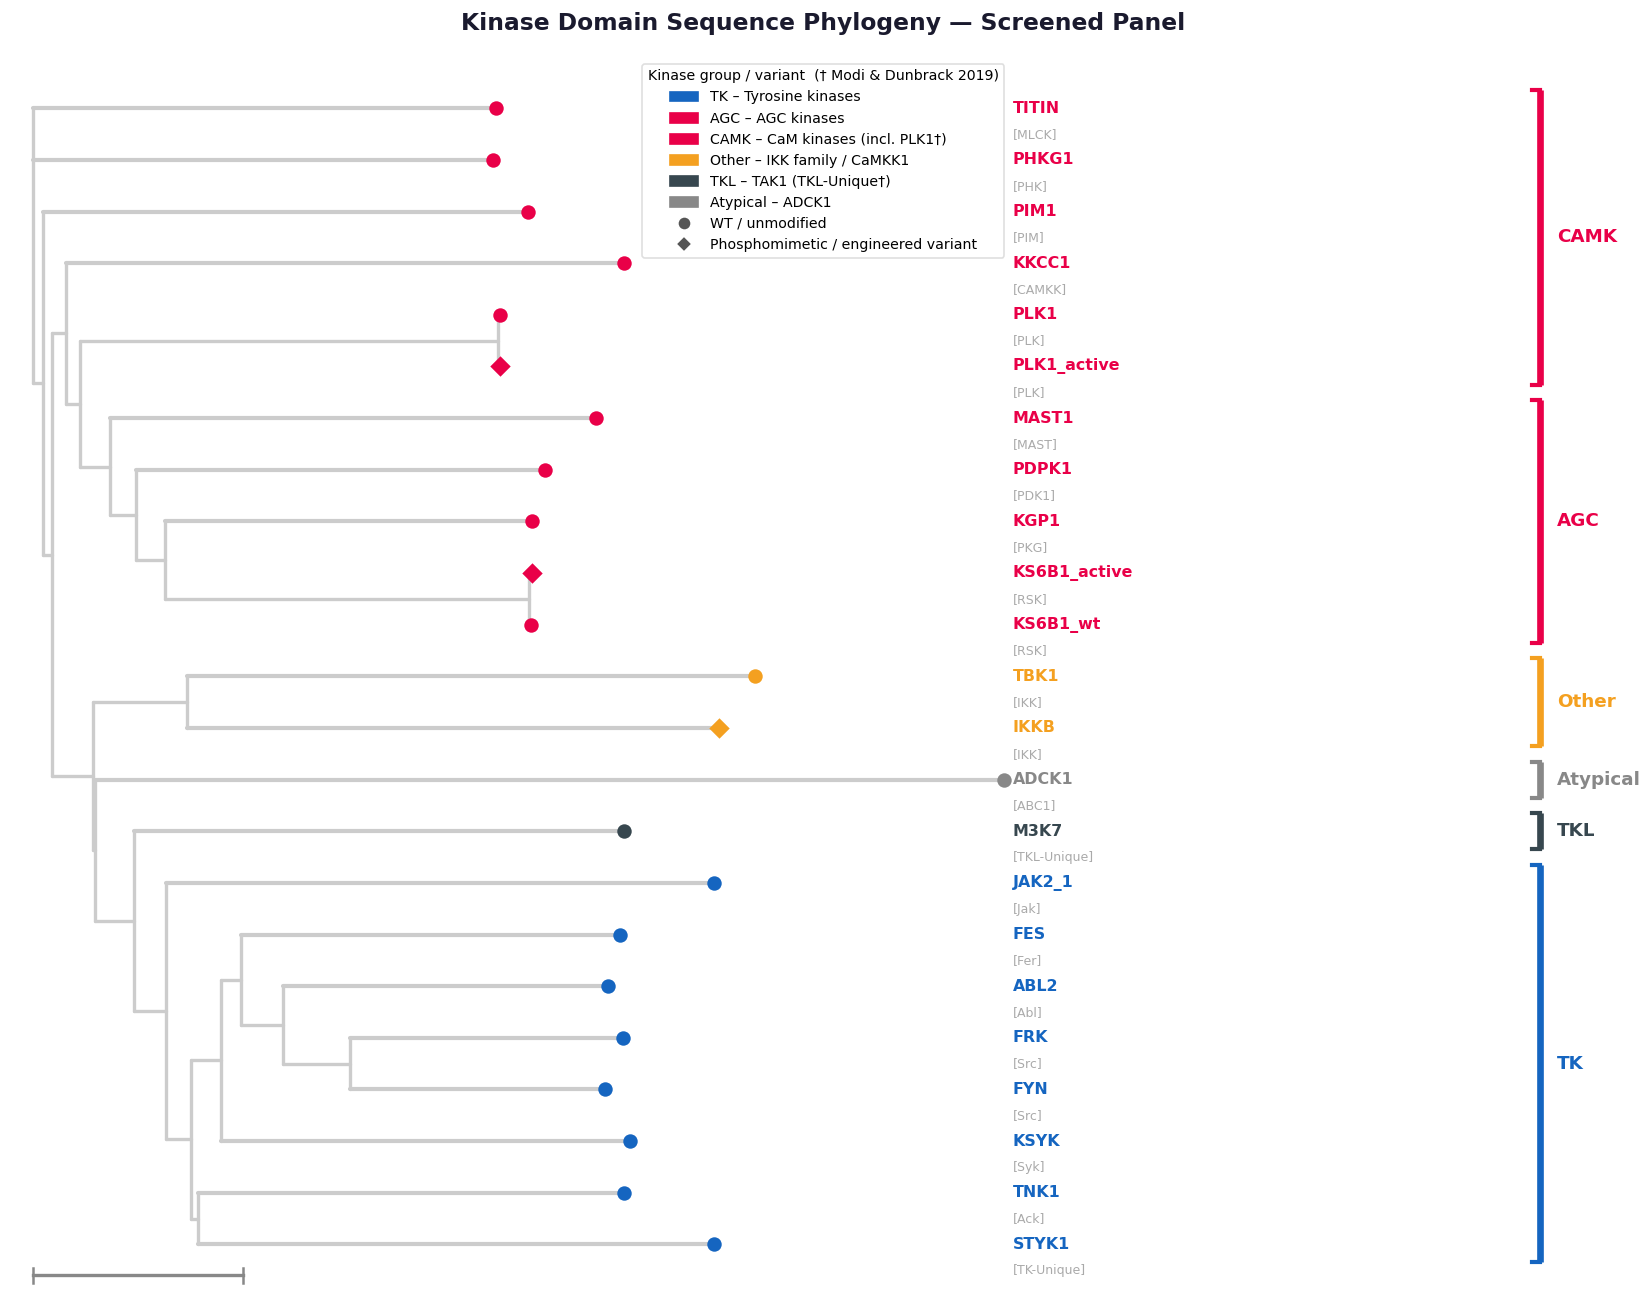

In [223]:
import re, copy
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from Bio import Phylo
from io import StringIO
from collections import defaultdict, Counter

# ── 1. Kinase classification ──────────────────────────────────────────────────
KINASE_CLASSIFICATION = {
    # key:              (screen_name,         gene,      group,       family,       uniprot)
    # AGC group
    "AGC_MAST1":        ("MAST1",             "MAST1",   "AGC",       "MAST",       "Q9Y2H9"),
    "AGC_PDPK1":        ("PDPK1",             "PDK1",    "AGC",       "PDK1",       "O15530"),
    "AGC_PKG1":         ("KGP1",              "PKG1",    "AGC",       "PKG",        "Q13976"),
    "AGC_RPS6KB1":      ("KS6B1_wt",          "p70S6K",  "AGC",       "RSK",        "P23443"),
    "AGC_RPS6KB1 T252D":      ("KS6B1_active",          "p70S6K",  "AGC",       "RSK",        "P23443"),
    # Atypical group
    "ATYPICAL_ADCK1":   ("ADCK1",             "ADCK1",   "Atypical",  "ABC1",       "Q86TW2"),
    # CAMK group
    "CAMK_TTN":         ("TITIN",             "TTN",     "CAMK",      "MLCK",       "Q8WZ42"),
    "CAMK_PHKG1":       ("PHKG1",             "PHKg1",   "CAMK",      "PHK",        "Q16816"),
    "CAMK_PIM1":        ("PIM1",              "PIM1",    "CAMK",      "PIM",        "P11309"),
    "CAMK_PLK1":        ("PLK1",              "PLK1",    "CAMK",      "PLK",        "P53350"),  # Modi & Dunbrack 2019
    "CAMK_PLK1 T210D":        ("PLK1_active",              "PLK1",    "CAMK",      "PLK",        "P53350"),  # Modi & Dunbrack 2019
    # Other group
    "OTHER_CAMKK1":     ("KKCC1",             "CaMKK1",  "CAMK",     "CAMKK",      "Q8N5S9"),
    "OTHER_IKBKB":      ("IKKB",              "IKKb",    "Other",     "IKK",        "O14920"),
    "OTHER_TBK1":       ("TBK1",              "TBK1",    "Other",     "IKK",        "Q9UHD2"),
    # TK group
    "TK_ABL2":          ("ABL2",              "ABL2",    "TK",        "Abl",        "P42684"),
    "TK_TNK1":          ("TNK1",              "TNK1",    "TK",        "Ack",        "Q13470"),
    "TK_FES":           ("FES",               "FES",     "TK",        "Fer",        "P07332"),
    "TK_JAK2_1":        ("JAK2_1",            "JAK2",    "TK",        "Jak",        "O60674"),
    "TK_FRK":           ("FRK",               "FRK",     "TK",        "Src",        "P42685"),
    "TK_FYN":           ("FYN",               "FYN",     "TK",        "Src",        "P06241"),
    "TK_KSYK":          ("KSYK",              "SYK",     "TK",        "Syk",        "P43405"),
    "TK_STYK1":         ("STYK1",             "SuRTK106","TK",        "TK-Unique",  "Q6J9G0"),
    # TKL group
    "TKL_MAP3K7":       ("M3K7",              "TAK1",    "TKL",       "TKL-Unique", "O43318"),  # Modi & Dunbrack 2019
}

# ── 2. Build SCREENED: tree_node_name -> (display_label, group, family) ───────
# Maps screen_name (used as tree leaf label) -> (display_label, group, family)
SCREENED = {
    v[0]: (v[0], v[2], v[3])
    for v in KINASE_CLASSIFICATION.values()
}
# Also map KS6B1_wt explicitly (tree may use this exact string)
# Add phosphomimetic mutants if present as separate leaves in the tree
MUTANT_SCREEN_NAMES = {"KS6B1_active", "PLK1_active", "IKKB"}

# ── 3. Colour palette keyed on group ─────────────────────────────────────────
GROUP_COLOR = {
    "TK":       "#1565c0",   # red
    "AGC":      "#e90048",   # blue
    "CAMK":     "#e90048",   # teal
    "Other":    "#F4A020",   # amber
    "TKL":      "#37474f",   # purple
    "Atypical": "#888888",   # grey
}

def get_color(group):
    return GROUP_COLOR.get(group, "#CCCCCC")

# ── 4. Load tree ──────────────────────────────────────────────────────────────
SEQ_TREE_PATH = "kinase_seq_tree_reordered.newick.nwk"

t = Phylo.read(SEQ_TREE_PATH, "newick")

# ── 5. Assign coordinates ─────────────────────────────────────────────────────
leaf_order = {c.name: i + 1 for i, c in enumerate(t.get_terminals())}
node_coords = {}

def build_coords(clade, depth=0.0):
    x = depth + (clade.branch_length or 0.0)
    if clade.is_terminal():
        y = float(leaf_order[clade.name])
    else:
        for c in clade.clades:
            build_coords(c, x)
        y = np.mean([node_coords[id(c)][1] for c in clade.clades])
    node_coords[id(clade)] = (x, y)

build_coords(t.root)

# ── 6. Branch colouring: majority group among screened terminals ──────────────
def majority_group_color(clade):
    groups = [
        SCREENED[c.name][1]
        for c in clade.get_terminals()
        if c.name in SCREENED
    ]
    if not groups:
        return "#CCCCCC"
    top_group = Counter(groups).most_common(1)[0][0]
    return get_color(top_group)

# ── 7. Draw branches ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 11))

def draw_clade(clade, parent_x=None):
    cx, cy = node_coords[id(clade)]
    col = majority_group_color(clade)
    lw = 2.5 if clade.is_terminal() else 2.0
    if parent_x is not None:
        ax.plot([parent_x, cx], [cy, cy], color='#CCCCCC', lw=lw,
                solid_capstyle='round', zorder=3)
    if not clade.is_terminal():
        child_ys = [node_coords[id(c)][1] for c in clade.clades]
        ax.plot([cx, cx], [min(child_ys), max(child_ys)], color='#CCCCCC', lw=lw,
                solid_capstyle='round', zorder=3)
        for c in clade.clades:
            draw_clade(c, parent_x=cx)

draw_clade(t.root)

# ── 8. Leaf dots and labels ───────────────────────────────────────────────────
x_max = max(x for x, y in node_coords.values())

# Nodes rendered as diamonds: phosphomimetic mutants and engineered variants
DIAMOND_NODES = {"KS6B1_active", "PLK1_active", "IKKB"}

for clade in t.get_terminals():
    if clade.name not in SCREENED:
        continue
    x, y = node_coords[id(clade)]
    label, group, family = SCREENED[clade.name]
    col = get_color(group)
    marker = "D" if clade.name in DIAMOND_NODES else "o"
    ax.scatter([x], [y], color=col, s=75, zorder=6, linewidths=0, marker=marker)
    ax.text(x_max + 0.004, y, label,
            color=col, fontsize=9.5, fontweight="bold",
            va="center", ha="left", zorder=7)
    ax.text(x_max + 0.004, y - 0.38, f"[{family}]",
            color="#AAAAAA", fontsize=7.5, va="top", ha="left", zorder=7)

# ── 9. Family bracket bars ────────────────────────────────────────────────────
group_ys = defaultdict(list)
for c in t.get_terminals():
    if c.name in SCREENED:
        group_ys[SCREENED[c.name][1]].append(node_coords[id(c)][1])

ax.set_xlim(-0.01, x_max + 0.30)
ax.set_ylim(0, len(SCREENED) + 1)
bracket_x = x_max + 0.255

for group, ys in group_ys.items():
    col = get_color(group)
    y0, y1 = min(ys) - 0.35, max(ys) + 0.35
    ymid = (y0 + y1) / 2
    ax.plot([bracket_x, bracket_x], [y0, y1], color=col, lw=4,
            solid_capstyle="butt", clip_on=False, zorder=5)
    for ytick in [y0, y1]:
        ax.plot([bracket_x - 0.004, bracket_x], [ytick, ytick],
                color=col, lw=2.5, clip_on=False, zorder=5)
    ax.text(bracket_x + 0.008, ymid, group,
            color=col, fontsize=11, fontweight="bold",
            va="center", ha="left", clip_on=False, zorder=7)

# ── 10. Scale bar ─────────────────────────────────────────────────────────────
sb_len = 0.1
ax.plot([0, sb_len],   [0.4, 0.4],   color="#888", lw=2)
ax.plot([0, 0],        [0.25, 0.55], color="#888", lw=1.5)
ax.plot([sb_len]*2,    [0.25, 0.55], color="#888", lw=1.5)
# ax.text(sb_len / 2, 0.0, "0.1 sub/site",
#         ha="center", va="top", fontsize=8, color="#888")

# ── 11. Legend ────────────────────────────────────────────────────────────────
group_labels = {
    "TK":       "TK – Tyrosine kinases",
    "AGC":      "AGC – AGC kinases",
    "CAMK":     "CAMK – CaM kinases (incl. PLK1†)",
    "Other":    "Other – IKK family / CaMKK1",
    "TKL":      "TKL – TAK1 (TKL-Unique†)",
    "Atypical": "Atypical – ADCK1",
}
handles = [
    mpatches.Patch(color=get_color(g), label=lbl)
    for g, lbl in group_labels.items()
]
handles += [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#555",
           markersize=8, label="WT / unmodified"),
    Line2D([0], [0], marker="D", color="w", markerfacecolor="#555",
           markersize=7, label="Phosphomimetic / engineered variant"),
]
ax.legend(
    handles=handles, loc="best", framealpha=0.93,
    fontsize=8.5, title="Kinase group / variant  († Modi & Dunbrack 2019)",
    title_fontsize=8.5, edgecolor="#DDD",
)

ax.set_title(
    "Kinase Domain Sequence Phylogeny — Screened Panel",
    fontsize=14, fontweight="bold", color="#1a1a2e", pad=16,
)
ax.axis("off")

plt.tight_layout()
plt.savefig("seq_tree.svg", dpi=180, bbox_inches="tight", facecolor="#F8F8F8")
plt.show()